In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import re
import ipaddress
import warnings

from urllib.parse import urlparse

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "PhiUSIIL_Phishing_URL_Dataset.csv",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["label"].value_counts())

print("\nTarget meaning:")
print("0 = Phishing")
print("1 = Legitimate")

Column names:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 235795

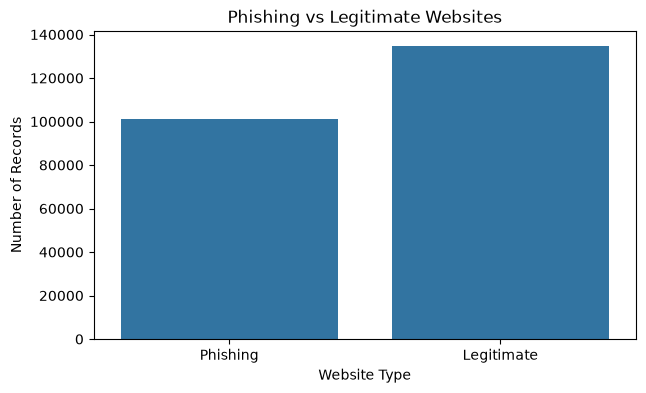

In [4]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="label")

plt.title("Phishing vs Legitimate Websites")
plt.xlabel("Website Type")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Phishing", "Legitimate"])

plt.show()

In [5]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove records with missing target
df = df.dropna(subset=["label"]).copy()

# Convert target into integer
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

# Separate target
y = df["label"]

# Select numerical features only
X = df.drop(columns=["label"], errors="ignore")

# Exclude text-based columns
X = X.select_dtypes(include=["number"])

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that contain no useful values
X = X.dropna(axis=1, how="all")

# Remove constant columns
X = X.loc[:, X.nunique(dropna=True) > 1]

print("Preprocessing completed!")
print("Feature count:", X.shape[1])
print("Feature names:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Preprocessing completed!
Feature count: 50
Feature names:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

X shape: (235795, 50)
y shape: (235795,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 188636
Testing records: 47159


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(max_iter=5000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

print("Four machine learning algorithms are ready!")

Four machine learning algorithms are ready!


In [8]:
for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    print(name, "training completed!")

print("\nAll models trained successfully!")


Training: Logistic Regression
Logistic Regression training completed!

Training: SVM
SVM training completed!

Training: Decision Tree
Decision Tree training completed!

Training: Naive Bayes
Naive Bayes training completed!

All models trained successfully!


In [9]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred) * 100,
        "Precision": precision_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ) * 100,
        "F1 Score": f1_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ) * 100
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nFinal Model Comparison:")
display(results_df.round(2))


 Logistic Regression
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20189
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


 SVM
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20189
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


 Decision Tree
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     20189
  Legitimate       1.00      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,99.99,100.00,99.97,99.99
1,SVM,99.99,100.00,99.98,99.99
2,Decision Tree,100.00,100.00,100.00,100.00
3,Naive Bayes,99.95,99.92,99.97,99.94


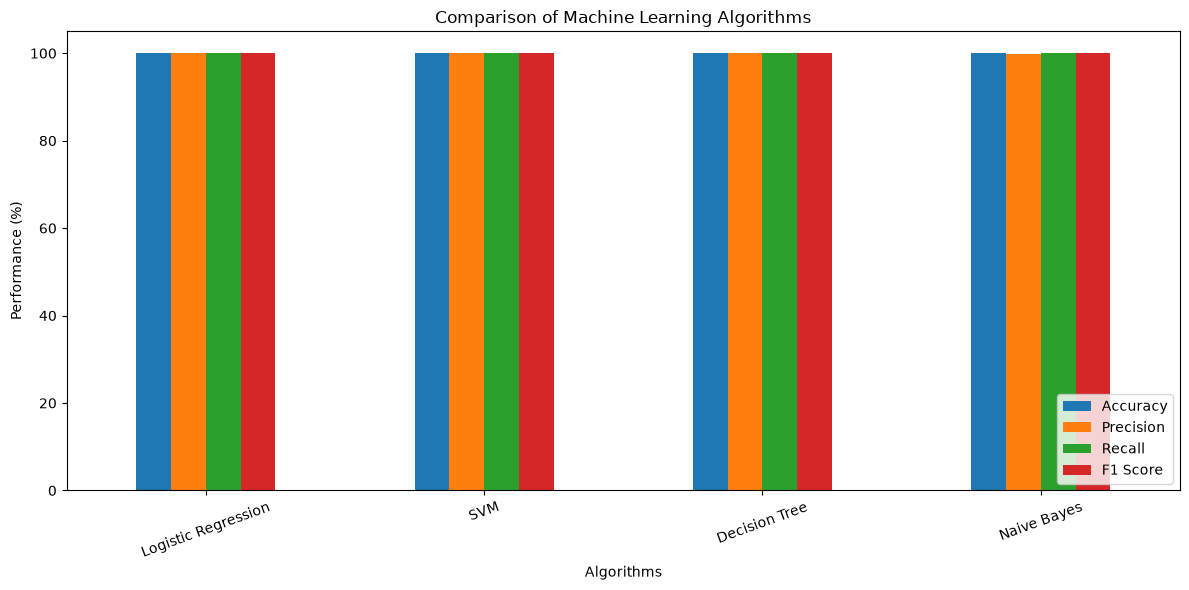

In [10]:
results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithms")
plt.ylabel("Performance (%)")
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

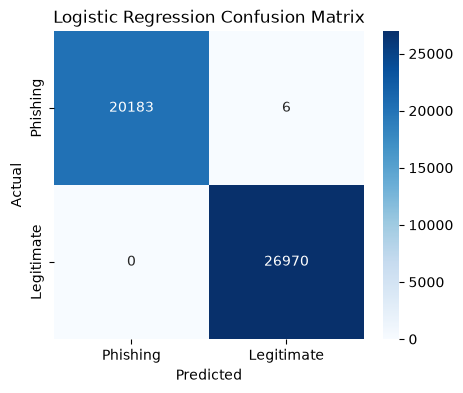

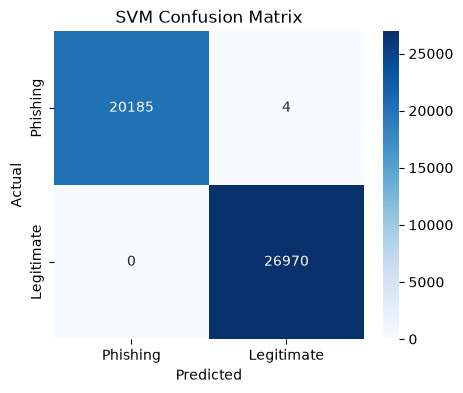

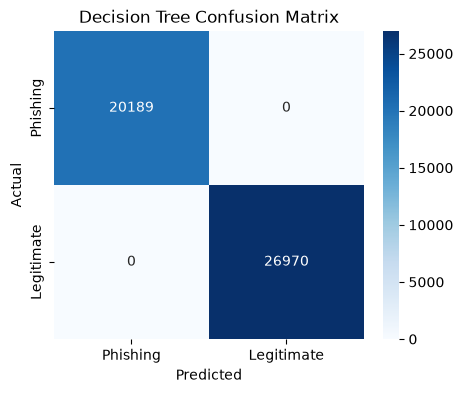

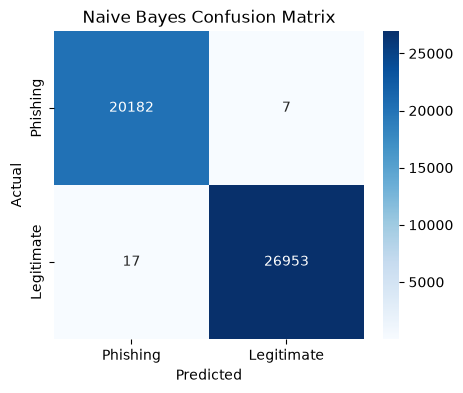

In [11]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Phishing", "Legitimate"],
        yticklabels=["Phishing", "Legitimate"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [12]:
best_index = results_df["F1 Score"].idxmax()

best_model_name = results_df.loc[best_index, "Algorithm"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Phishing F1 Score:",
      round(results_df.loc[best_index, "F1 Score"], 2), "%")

Best Model: Decision Tree
Phishing F1 Score: 100.0 %


In [13]:
model_bundle = {
    "models": models,
    "feature_names": list(X.columns),
    "best_model_name": best_model_name
}

joblib.dump(model_bundle, "phishing_models.pkl")

print("All trained models saved successfully!")

All trained models saved successfully!


In [14]:
def extract_url_features(url):

    url = str(url).strip()

    if not url.startswith(("http://", "https://")):
        url = "https://" + url

    parsed = urlparse(url)
    domain = parsed.hostname or ""

    # Check whether domain is an IP address
    try:
        ipaddress.ip_address(domain)
        ip_address = 1
    except ValueError:
        ip_address = 0

    suspicious_words = [
        "login", "verify", "update", "secure",
        "account", "banking", "password", "confirm"
    ]

    shortener_domains = [
        "bit.ly", "tinyurl.com", "t.co",
        "is.gd", "cutt.ly"
    ]

    features = {
        "URLLength": len(url),
        "DomainLength": len(domain),
        "IsDomainIP": ip_address,
        "IsHTTPS": int(parsed.scheme == "https"),
        "NoOfDots": url.count("."),
        "NoOfHyphens": url.count("-"),
        "NoOfAt": url.count("@"),
        "NoOfQuestionMarks": url.count("?"),
        "NoOfEqual": url.count("="),
        "NoOfPercent": url.count("%"),
        "NoOfAmpersand": url.count("&"),
        "NoOfDigits": sum(c.isdigit() for c in url),
        "NoOfSubDomain": max(0, domain.count(".") - 1),
        "PathLength": len(parsed.path),
        "QueryLength": len(parsed.query),
        "HasSuspiciousWord": int(
            any(word in url.lower() for word in suspicious_words)
        ),
        "HasShortener": int(
            any(domain.lower() == s for s in shortener_domains)
        )
    }

    return features


# Test feature extraction
test_url = "https://example.com"

display(pd.DataFrame([extract_url_features(test_url)]))

,URLLength,DomainLength,IsDomainIP,IsHTTPS,NoOfDots,NoOfHyphens,NoOfAt,NoOfQuestionMarks,NoOfEqual,NoOfPercent,NoOfAmpersand,NoOfDigits,NoOfSubDomain,PathLength,QueryLength,HasSuspiciousWord,HasShortener
0,19,11,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0


In [15]:
# Check whether original URL column exists
if "URL" not in df.columns:
    raise ValueError(
        "URL column not found. Check the dataset column names."
    )

# Extract original URLs and labels
url_df = df[["URL", "label"]].dropna().copy()

# Extract features for all dataset URLs
url_X = pd.DataFrame(
    [extract_url_features(u) for u in url_df["URL"]]
)

url_y = url_df["label"].astype(int)

print("URL-only dataset created!")
print("URL features shape:", url_X.shape)

display(url_X.head())

URL-only dataset created!
URL features shape: (235795, 17)


,URLLength,DomainLength,IsDomainIP,IsHTTPS,NoOfDots,NoOfHyphens,NoOfAt,NoOfQuestionMarks,NoOfEqual,NoOfPercent,NoOfAmpersand,NoOfDigits,NoOfSubDomain,PathLength,QueryLength,HasSuspiciousWord,HasShortener
0,32,24,0,1,2,0,0,0,0,0,0,0,1,0,0,0,0
1,24,16,0,1,2,1,0,0,0,0,0,0,1,0,0,0,0
2,30,22,0,1,3,0,0,0,0,0,0,0,2,0,0,0,0
3,27,19,0,1,2,0,0,0,0,0,0,0,1,0,0,0,0
4,34,26,0,1,2,0,0,0,0,0,0,0,1,0,0,0,0


In [16]:
UX_train, UX_test, Uy_train, Uy_test = train_test_split(
    url_X,
    url_y,
    test_size=0.20,
    random_state=42,
    stratify=url_y
)

url_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(max_iter=5000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

for name, model in url_models.items():

    print("Training:", name)

    model.fit(UX_train, Uy_train)

print("\nAll URL-only models trained successfully!")

Training: Logistic Regression
Training: SVM
Training: Decision Tree
Training: Naive Bayes

All URL-only models trained successfully!


In [17]:
url_results = []

for name, model in url_models.items():

    prediction = model.predict(UX_test)

    url_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(
            Uy_test, prediction
        ) * 100,

        "Precision": precision_score(
            Uy_test, prediction, pos_label=0, zero_division=0
        ) * 100,

        "Recall": recall_score(
            Uy_test, prediction, pos_label=0, zero_division=0
        ) * 100,

        "F1 Score": f1_score(
            Uy_test, prediction, pos_label=0, zero_division=0
        ) * 100
    })

url_results_df = pd.DataFrame(url_results)

display(url_results_df.round(2))

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,99.12,99.88,98.05,98.96
1,SVM,99.27,99.99,98.31,99.14
2,Decision Tree,99.54,99.90,99.02,99.46
3,Naive Bayes,99.27,99.88,98.41,99.14


In [18]:
# Enter a website URL
user_url = input("Enter Website URL: ")

# Extract URL features
new_data = pd.DataFrame([
    extract_url_features(user_url)
])

# Predict using all four algorithms
print("\nWebsite:", user_url)
print("\nPrediction Results:")

predictions = []

for name, model in url_models.items():

    prediction = model.predict(new_data)[0]

    if prediction == 0:
        result = "PHISHING WEBSITE"
    else:
        result = "LEGITIMATE WEBSITE"

    predictions.append(prediction)

    print(name, ":", result)

# Final result by majority voting
phishing_votes = predictions.count(0)
legitimate_votes = predictions.count(1)

print("\nFinal Prediction:")

if phishing_votes > legitimate_votes:
    print("WARNING: PHISHING WEBSITE")
elif legitimate_votes > phishing_votes:
    print("RESULT: LEGITIMATE WEBSITE")
else:
    print("RESULT: INCONCLUSIVE - MODELS DISAGREE")

Enter Website URL:  https://example.com



Website: https://example.com

Prediction Results:
Logistic Regression : LEGITIMATE WEBSITE
SVM : LEGITIMATE WEBSITE
Decision Tree : PHISHING WEBSITE
Naive Bayes : LEGITIMATE WEBSITE

Final Prediction:
RESULT: LEGITIMATE WEBSITE


In [19]:
url_model_bundle = {
    "models": url_models,
    "feature_names": list(url_X.columns)
}

joblib.dump(
    url_model_bundle,
    "phishing_url_models.pkl"
)

print("URL prediction models saved successfully!")

URL prediction models saved successfully!
